In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("GE_OE_Cleaned_Data.csv")
print(df)

             Timestamp 3) What is your gender?  \
0   8/19/2026 10:57:56                    Male   
1    8/30/2026 7:55:20                    Male   
2    8/30/2026 9:28:03                    Male   
3   8/30/2026 10:11:59                    Male   
4   8/30/2026 10:32:12                    Male   
..                 ...                     ...   
87   9/8/2026 21:23:20                    Male   
88   9/8/2026 22:21:36                    Male   
89   9/8/2026 23:52:38                    Male   
90   9/9/2026 12:02:56                    Male   
91   9/9/2026 12:19:46                  Female   

   4) Which course/program are you studying?  \
0                                       B.SC   
1                                       B.SC   
2                                       B.SC   
3                                       B.SC   
4                                       B.SC   
..                                       ...   
87                                       B.A   
88             

In [2]:
import pandas as pd
from scipy.stats import chi2_contingency

# Select the two survey questions
perception_col = [
    c for c in df.columns
    if "complement my core curriculum well" in c
][0]

satisfaction_col = [
    c for c in df.columns
    if "Overall, how satisfied" in c
][0]

# Create a contingency table
data = df[[perception_col, satisfaction_col]].dropna()

table = pd.crosstab(
    data[perception_col],
    data[satisfaction_col]
)

print("Contingency Table:")
print(table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(table)

print("\nChi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", round(p_value, 4))

# Interpret the result
if p_value < 0.05:
    print("Reject the Null Hypothesis (H0).")
    print("There is a significant association.")
else:
    print("Fail to reject the Null Hypothesis (H0).")
    print("No significant association was established.")

Contingency Table:
 19) Overall, how satisfied are you with the  GE/OE   subjects offered by your college?     Dissatisfied  \
11)  Rate the following on a 5-point scale (1 =...                                                         
1.0                                                                                                    2   
2.0                                                                                                    3   
3.0                                                                                                    3   
4.0                                                                                                    0   
5.0                                                                                                    2   

 19) Overall, how satisfied are you with the  GE/OE   subjects offered by your college?     Neutral  \
11)  Rate the following on a 5-point scale (1 =...                                                    
1.0               

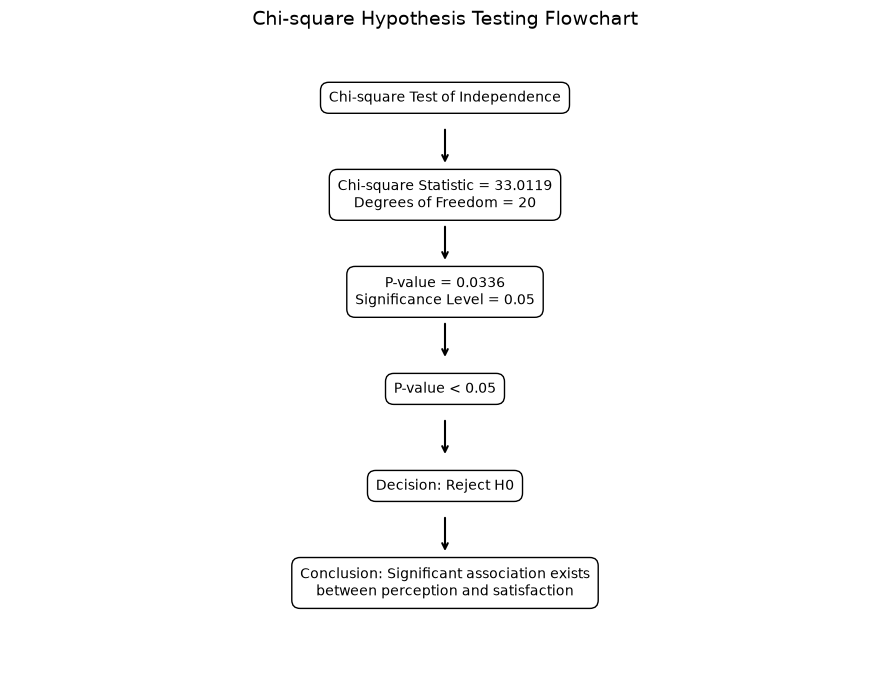

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

steps = [
    ("Chi-square Test of Independence", 9),
    ("Chi-square Statistic = 33.0119\nDegrees of Freedom = 20", 7.5),
    ("P-value = 0.0336\nSignificance Level = 0.05", 6),
    ("P-value < 0.05", 4.5),
    ("Decision: Reject H0", 3),
    ("Conclusion: Significant association exists\nbetween perception and satisfaction", 1.5)
]

for text, y in steps:
    ax.text(
        5, y, text,
        ha="center", va="center",
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.6", 
                  facecolor="white", edgecolor="black")
    )

for i in range(len(steps) - 1):
    ax.annotate(
        "",
        xy=(5, steps[i + 1][1] + 0.45),
        xytext=(5, steps[i][1] - 0.45),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

plt.title("Chi-square Hypothesis Testing Flowchart",
          fontsize=14)
plt.tight_layout()
plt.show()

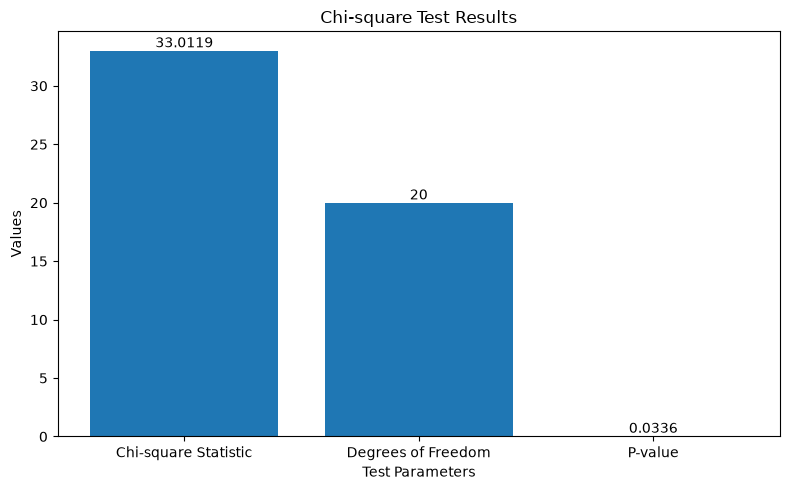

In [4]:
import matplotlib.pyplot as plt

# Chi-square test results
labels = ["Chi-square Statistic", "Degrees of Freedom", "P-value"]
values = [33.0119, 20, 0.0336]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.title("Chi-square Test Results")
plt.xlabel("Test Parameters")
plt.ylabel("Values")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()